In [5]:
#!pip install nltk wordcloud tensorflow

In [4]:
import os
import email
import pandas as pd
import numpy as np
from tqdm import tqdm
import gc
from os import path
import re
import csv
import tensorflow as tf
from datetime import datetime
import pickle
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
from collections import Counter
from nltk.tokenize import sent_tokenize
from nltk.translate.bleu_score import sentence_bleu
from sklearn.utils import shuffle
import nltk
import random
from nltk import bigrams, trigrams
from collections import Counter, defaultdict
from multiprocessing import Pool
from nltk.corpus import reuters

In [ ]:
df = pd.read_csv("./emails_subset.csv")
#df = df.sample(random_state=42)
df.reset_index(inplace=True, drop=True)

df.head(5)

,file,message
0,fossum-d/sent/11.,Message-ID: <15431600.1075842491724.JavaMail.e...
1,fossum-d/sent/110.,Message-ID: <13215487.1075842494887.JavaMail.e...
2,fossum-d/sent/1100.,Message-ID: <29940373.1075842557853.JavaMail.e...
3,fossum-d/sent/1101.,Message-ID: <25591175.1075842557876.JavaMail.e...
4,fossum-d/sent/1102.,Message-ID: <10170099.1075842557925.JavaMail.e...


In [11]:
df.shape

(23724, 2)

In [12]:
df['message'][0]

'Message-ID: <15431600.1075842491724.JavaMail.evans@thyme>\nDate: Fri, 17 Dec 1999 00:20:00 -0800 (PST)\nFrom: drew.fossum@enron.com\nTo: michel.nelson@enron.com\nSubject: Re: EES\nMime-Version: 1.0\nContent-Type: text/plain; charset=us-ascii\nContent-Transfer-Encoding: 7bit\nX-From: Drew Fossum\nX-To: Michel Nelson\nX-cc: \nX-bcc: \nX-Folder: \\Drew_Fossum_Dec2000_June2001_1\\Notes Folders\\Sent\nX-Origin: FOSSUM-D\nX-FileName: dfossum.nsf\n\n   \n\t\n\t\n\tFrom:  Michel Nelson                           12/16/99 05:50 PM\n\t\n\nTo: Drew Fossum/ET&S/Enron@ENRON\ncc: Rich Jolly/ET&S/Enron@Enron, Shelley Corman/ET&S/Enron@ENRON, Maria \nPavlou/ET&S/Enron@ENRON, Mary Kay Miller/ET&S/Enron@ENRON \n\nSubject: Re: EES  \n\nRich - Is this really worth the hassle? All the upside is on the side of EES, \nall the downside (work) appears to be on our side. It would appear to me that \nEES could rent an office in some executive office space provider .....but \nmaybe I don\'t have my Enron hat on.\

In [13]:
def body(messages):
    column = []
    for message in messages:
        e = email.message_from_string(message)
        column.append(e.get_payload())
    return column

In [14]:
df['content'] = body(df['message'])
df.head()

,file,message,content
0,fossum-d/sent/11.,Message-ID: <15431600.1075842491724.JavaMail.e...,\n\t\n\t\n\tFrom: Michel Nelson ...
1,fossum-d/sent/110.,Message-ID: <13215487.1075842494887.JavaMail.e...,I just talked to Frank about my revised draft ...
2,fossum-d/sent/1100.,Message-ID: <29940373.1075842557853.JavaMail.e...,"More specifically, this is the ECS Gallup mtg-..."
3,fossum-d/sent/1101.,Message-ID: <25591175.1075842557876.JavaMail.e...,"dan--pls hookl this up for me, I'm too dumb. ..."
4,fossum-d/sent/1102.,Message-ID: <10170099.1075842557925.JavaMail.e...,see--I am dumb! thanks dan. df\n\n\nFrom: Da...


### Processing the content

In [15]:
# Remove newline characters
df.content = df.content.str.replace("\n", "")

# Remove all non-alphanumeric characters and replace them with spaces
df.content = df.content.apply(lambda x: re.sub('[^A-Za-z0-9]+', ' ', x))

# Convert all content to lowercase
df.content = df.content.str.lower()

# Remove leading and trailing spaces
df.content = df.content.str.strip()

In [16]:
df.head()

,file,message,content
0,fossum-d/sent/11.,Message-ID: <15431600.1075842491724.JavaMail.e...,from michel nelson 12 16 99 05 50 pm to drew f...
1,fossum-d/sent/110.,Message-ID: <13215487.1075842494887.JavaMail.e...,i just talked to frank about my revised draft ...
2,fossum-d/sent/1100.,Message-ID: <29940373.1075842557853.JavaMail.e...,more specifically this is the ecs gallup mtg k...
3,fossum-d/sent/1101.,Message-ID: <25591175.1075842557876.JavaMail.e...,dan pls hookl this up for me i m too dumb dffr...
4,fossum-d/sent/1102.,Message-ID: <10170099.1075842557925.JavaMail.e...,see i am dumb thanks dan dffrom dan bunch enro...


### Tokenization 

In [17]:
# Split the content into an array of tokens
df['body_list'] = df.content.apply(lambda x: x.split())

# Display the first 5 rows
df.head()

,file,message,content,body_list
0,fossum-d/sent/11.,Message-ID: <15431600.1075842491724.JavaMail.e...,from michel nelson 12 16 99 05 50 pm to drew f...,"[from, michel, nelson, 12, 16, 99, 05, 50, pm,..."
1,fossum-d/sent/110.,Message-ID: <13215487.1075842494887.JavaMail.e...,i just talked to frank about my revised draft ...,"[i, just, talked, to, frank, about, my, revise..."
2,fossum-d/sent/1100.,Message-ID: <29940373.1075842557853.JavaMail.e...,more specifically this is the ecs gallup mtg k...,"[more, specifically, this, is, the, ecs, gallu..."
3,fossum-d/sent/1101.,Message-ID: <25591175.1075842557876.JavaMail.e...,dan pls hookl this up for me i m too dumb dffr...,"[dan, pls, hookl, this, up, for, me, i, m, too..."
4,fossum-d/sent/1102.,Message-ID: <10170099.1075842557925.JavaMail.e...,see i am dumb thanks dan dffrom dan bunch enro...,"[see, i, am, dumb, thanks, dan, dffrom, dan, b..."


### EDA

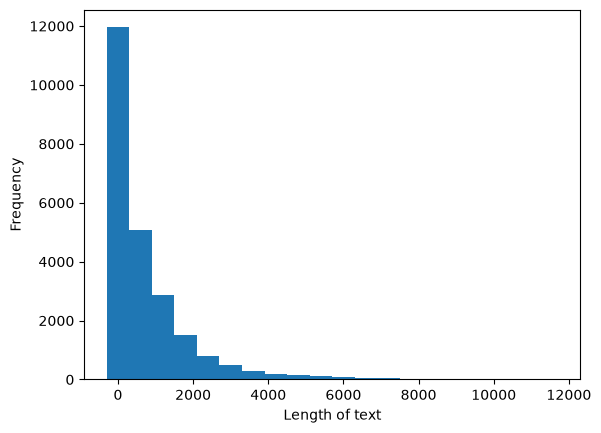

In [18]:
if __name__ == "__main__":
    # EDA for text length
    x = list(df['content'].apply(lambda x: len(x)))

    # Plot the distribution of email text lengths
    plt.hist(x, range=[1, 12000], bins=20, align='left')

    # Set figure size
    plt.rcParams["figure.figsize"] = (10, 4)

    # Set axis labels
    plt.xlabel("Length of text")
    plt.ylabel("Frequency")

In [19]:
if __name__ == "__main__":
    for i in range(0, 110, 10):
        print("{}th- percentile of len(text) is {}".format(i, np.percentile(x, i)))
        print("=" * 40)

x = None
del(x)
gc.collect()

0th- percentile of len(text) is 0.0
10th- percentile of len(text) is 83.0
20th- percentile of len(text) is 170.0
30th- percentile of len(text) is 276.0
40th- percentile of len(text) is 420.0
50th- percentile of len(text) is 596.0
60th- percentile of len(text) is 835.0
70th- percentile of len(text) is 1139.0
80th- percentile of len(text) is 1551.0
90th- percentile of len(text) is 2389.0
100th- percentile of len(text) is 92570.0


3701

### Observations

- The length of the email text ranges from 0 to 92,570 characters.
- The distribution of text length is right-skewed, with a long tail of unusually long emails.
- Short emails occur more frequently than long emails.
- Based on the percentile values, 90% of emails contain at most 2,389 characters.
- The median email length (50th percentile) is 596 characters.
- The maximum length of 92,570 characters indicates the presence of a few very long emails, which may be considered outliers relative to the majority of the dataset.

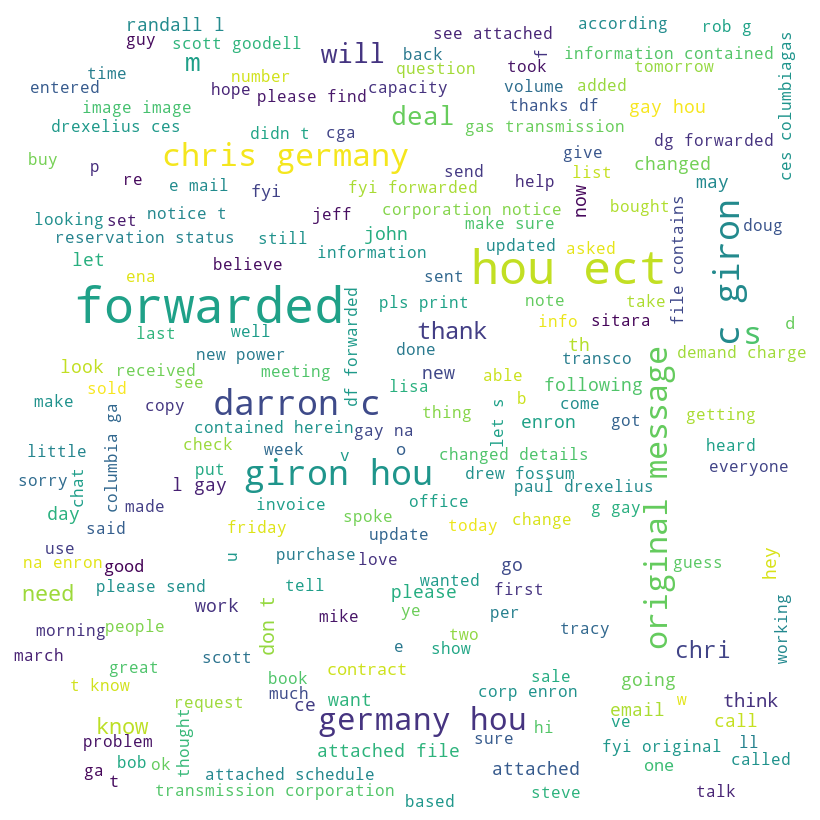

In [20]:
if __name__ == "__main__":
    # Word cloud for content, X-TO, X-From
    wordcloud = WordCloud(
        width=800,
        height=800,
        background_color='white',
        stopwords=STOPWORDS,
        max_font_size=50,
        min_font_size=10
    ).generate(df['content'].to_string())

    # Plot the WordCloud image
    plt.figure(figsize=(8, 8), facecolor=None)
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.tight_layout(pad=0)

    plt.show()

In [21]:
# Most frequent words
def word_count(str):
    """
    Function that gets a string and counts each word in the string
    """
    counts = dict()
    words = str.split()

    for word in words:
        if word in counts:
            counts[word] += 1
        elif len(word) > 2:
            counts[word] = 1

    return counts

In [22]:
if __name__ == "__main__":
    # Most 100 frequent words in content
    most_frequent_words = Counter(
        word_count(str(df['content'].to_string()))
    ).most_common(100)

    print('\n'.join(map(str, most_frequent_words)))

    most_frequent_words = None
    del(most_frequent_words)
    gc.collect()

('the', 6913)
('...', 3840)
('you', 3791)
('forwarded', 3542)
('hou', 2833)
('ect', 2791)
('for', 2386)
('this', 2316)
('from', 1896)
('and', 1826)
('chris', 1821)
('have', 1668)
('darron', 1459)
('2...', 1456)
('are', 1451)
('giron', 1398)
('original', 1260)
('germany', 1218)
('message', 1203)
('please', 1118)
('20...', 1080)
('with', 982)
('that', 956)
('just', 880)
('will', 858)
('attached', 807)
('deal', 784)
('thanks', 743)
('what', 655)
('enron', 650)
('not', 643)
('sent', 629)
('has', 619)
('your', 610)
('know', 582)
('all', 577)
('gas', 566)
('ces', 565)
('here', 553)
('get', 528)
('was', 525)
('t...', 518)
('can', 516)
('need', 511)
('about', 496)
('hey', 494)
('would', 491)
('see', 482)
('new', 453)
('don', 450)
('our', 446)
('out', 443)
('fyi', 434)
('think', 414)
('john', 407)
('s...', 393)
('like', 367)
('good', 363)
('following', 361)
('let', 351)
('but', 350)
('call', 350)
('how', 350)
('been', 349)
('gay', 345)
('day', 324)
('2000', 319)
('file', 318)
('changed', 311)
(

In [23]:
shuffle_df = df.sample(frac=1, random_state=42)

# Define a size for your train set
train_size = int(0.7 * len(df))

# Split your dataset
train_set = shuffle_df[:train_size]
train_set.reset_index(inplace=True, drop=True)

test_set = shuffle_df[train_size:].copy()
test_set.reset_index(inplace=True, drop=True)

In [ ]:
df = train_set.copy()
df.head()

,file,message,content,body_list
0,germany-c/deleted_items/233.,Message-ID: <16345727.1075852111920.JavaMail.e...,original message from navigator nisource com m...,"[original, message, from, navigator, nisource,..."
1,geaccone-t/inbox/188.,Message-ID: <16792393.1075859045156.JavaMail.e...,please review and get back to me asap rod hays...,"[please, review, and, get, back, to, me, asap,..."
2,giron-d/deleted_items/314.,Message-ID: <21035669.1075852225153.JavaMail.e...,the 5 day roll figure has been corrected 10 25...,"[the, 5, day, roll, figure, has, been, correct..."
3,giron-d/_sent_mail/599.,Message-ID: <12690247.1075854423571.JavaMail.e...,forwarded by darron c giron hou ect on 10 13 2...,"[forwarded, by, darron, c, giron, hou, ect, on..."
4,griffith-j/all_documents/99.,Message-ID: <263963.1075849634966.JavaMail.eva...,attached is a revised form of credit letter pl...,"[attached, is, a, revised, form, of, credit, l..."


In [25]:
corpus = df['body_list'].to_list()

### Bigram

In [26]:
def build_bigram_model(corpus):
    # Create a placeholder for model
    bigram_model1 = defaultdict(lambda: defaultdict(lambda: 0))

    # Count frequency of co-occurrence
    for sentence in corpus:
        for w1, w2 in bigrams(sentence, pad_right=True, pad_left=True):
            bigram_model1[w1][w2] += 1

    # Let's transform the counts to probabilities
    for w1 in bigram_model1:
        print(w1)
        break

        total_count = float(sum(bigram_model1[w1].values()))
        for w2 in bigram_model1[w1]:
            bigram_model1[w1][w2] /= total_count

    return bigram_model1

In [27]:
bigram = build_bigram_model(corpus)

None


In [28]:

def get_next_word(model, input_string):
    if len(input_string.split()) > 1:
        input_string_ = input_string.split()
        output = dict(model[tuple(input_string_)])
        return "{} {}".format(
            input_string,
            list({
                k: v for k, v in sorted(
                    output.items(),
                    key=lambda item: item[1],
                    reverse=True
                )
            })[0]
        )
    else:
        input_string = (input_string)
        output = dict(model[input_string])
        return "{} {}".format(
            input_string,
            list({
                k: v for k, v in sorted(
                    output.items(),
                    key=lambda item: item[1],
                    reverse=True
                )
            })[0]
        )

In [29]:

get_next_word(bigram, 'how')
# Output: 'how to'

'how to'

In [30]:
get_next_word(bigram, 'they')

'they are'

In [31]:
get_next_word(bigram, 'i')

'i m'

In [32]:
get_next_word(bigram, 'why')

'why don'

In [33]:
get_next_word(bigram, 'cannot')

'cannot be'

In [35]:
get_next_word(bigram, 'hello')

'hello all'

In [36]:
def complete_sentence(model, input_str, count, ngrams=2):

    for i in range(count):
        curr_ngram = input_str.split()[-ngrams+1:]
        curr_ngram = " ".join(curr_ngram)
        nxt_word = get_next_word(model, curr_ngram).split()[-1]

        input_str += ' ' + nxt_word
        print('Step ' + str(i) + ' ' + input_str)

In [37]:
complete_sentence(bigram, 'can', 10)

Step 0 can you
Step 1 can you have
Step 2 can you have any
Step 3 can you have any questions
Step 4 can you have any questions please
Step 5 can you have any questions please let
Step 6 can you have any questions please let me
Step 7 can you have any questions please let me know
Step 8 can you have any questions please let me know if
Step 9 can you have any questions please let me know if you


In [38]:
complete_sentence(bigram, 'if', 10)

Step 0 if you
Step 1 if you have
Step 2 if you have any
Step 3 if you have any questions
Step 4 if you have any questions please
Step 5 if you have any questions please let
Step 6 if you have any questions please let me
Step 7 if you have any questions please let me know
Step 8 if you have any questions please let me know if
Step 9 if you have any questions please let me know if you
